# Model 6: Stroke risk classification with logistic regression

### Authors
   * Jonathan Sancho Loaiza
   * Jennifer Lopez Miranda
   * Magdaleno Gomez Diaz

## Problem Analysis (CRISP-DM 1: Business Understanding)

A stroke is a blockage or a rupture of a blood vessel in the brain, and most of the damage it causes depends on how fast the person reaches a hospital. A screening tool that flags the people most at risk, from facts a nurse can collect in a minute, lets a clinic call those people for a check-up before the event rather than after. The question this notebook answers is whether the risk of stroke can be predicted from age, blood pressure, heart disease, glucose, body mass and a few lifestyle facts, well enough for the assistant of the project to give a person a risk level when asked.

The dataset is the stroke prediction file published on Kaggle by fedesoriano, with 5,110 people and, for each one, whether they had a stroke. The technique is logistic regression, taught in week eleven. Instead of predicting a number it predicts a probability between 0 and 1 by passing a linear combination of the predictors through the sigmoid function, and a threshold on that probability turns it into a yes or no. That threshold is a decision taken after training, and in a medical screening it is the most important decision of the notebook, because missing a person who will have a stroke costs far more than sending a healthy person to a check-up.

### Libraries

In [1]:
# Dataset handling
import os
import kagglehub
import numpy as np
import pandas as pd

# Plots
import matplotlib.pyplot as plt
import seaborn as sns

# Model
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Split, evaluation and persistence
from sklearn.model_selection import train_test_split
from sklearn.metrics import (confusion_matrix, accuracy_score, recall_score, precision_score,
                             f1_score, roc_auc_score, roc_curve, classification_report)
import joblib

%matplotlib inline

RANDOM_STATE = 42

# Folder shared by every model of the project, read later by the REST API
MODELS_DIR = os.path.join('..', 'models')
os.makedirs(MODELS_DIR, exist_ok=True)

/home/jony/ai-project/env/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Data Understanding (CRISP-DM 2)

The dataset is downloaded through kagglehub, which caches it locally and returns the folder, so the cell works unchanged on a local machine and in Google Colab.

In [2]:
path = kagglehub.dataset_download('fedesoriano/stroke-prediction-dataset')
print('Path to dataset files:', path)
stroke = pd.read_csv(os.path.join(path, 'healthcare-dataset-stroke-data.csv'))
stroke.head()

Path to dataset files: /home/jony/.cache/kagglehub/datasets/fedesoriano/stroke-prediction-dataset/versions/1


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


Each row is a person. `id` is an identifier with no information, `gender`, `age`, `hypertension` and `heart_disease` are the medical basics, with the last two coded 1 for yes and 0 for no, `ever_married`, `work_type` and `Residence_type` are lifestyle facts, `avg_glucose_level` is the blood glucose in mg/dL, `bmi` the body mass index, `smoking_status` has four values, and `stroke` is the target, 1 if the person had a stroke. The first row is a 67 year old man with heart disease, a glucose of 229 and a stroke.

In [3]:
print("Rows and columns:", stroke.shape)
stroke.info()
print("Duplicated rows:", stroke.duplicated().sum())

Rows and columns: (5110, 12)
<class 'pandas.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   str    
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   str    
 6   work_type          5110 non-null   str    
 7   Residence_type     5110 non-null   str    
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   str    
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), str(5)
memory usage: 479.2 KB
Duplicated rows: 0


There are 5,110 people and 12 columns. Five columns are text and will need encoding. `bmi` is the only column with missing values, 4,909 non null out of 5,110, so 201 people have no body mass recorded. No row is duplicated.

In [4]:
stroke.describe().round(2)

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.00,5110.00,5110.0,5110.00,5110.00,4909.00,5110.00
mean,36517.83,43.23,0.1,0.05,106.15,28.89,0.05
std,21161.72,22.61,0.3,0.23,45.28,7.85,0.22
min,67.00,0.08,0.0,0.00,55.12,10.30,0.00
25%,17741.25,25.00,0.0,0.00,77.24,23.50,0.00
50%,36932.00,45.00,0.0,0.00,91.88,28.10,0.00
75%,54682.00,61.00,0.0,0.00,114.09,33.10,0.00
max,72940.00,82.00,1.0,1.00,271.74,97.60,1.00


Age runs from 0.08 to 82 years with a median of 45, so the file includes babies and children, who almost never have strokes and will pull the base rate down. Ten percent of the people have hypertension and 5 percent heart disease. Glucose has a median of 92 mg/dL but a maximum of 272, a diabetic level. The body mass index has a median of 28 and a maximum of 97.6, which is far beyond any plausible value and is treated as it comes, since there is no way to know the true value. The mean of `stroke` is 0.05, which is the first important number of the notebook: only about five people in a hundred had a stroke.

        People  Share %
stroke                 
0         4861     95.1
1          249      4.9


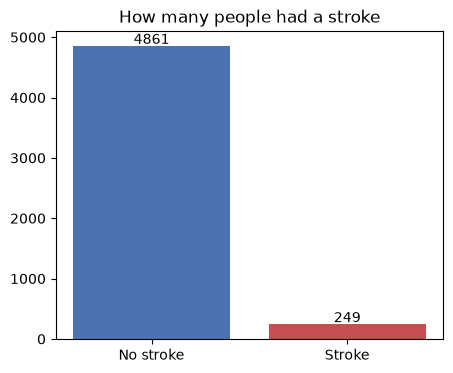

In [5]:
# The target, in counts and in percentage
counts = stroke['stroke'].value_counts()
print(pd.DataFrame({'People': counts, 'Share %': (counts / len(stroke) * 100).round(1)}))

plt.figure(figsize=(5, 4))
plt.bar(['No stroke', 'Stroke'], counts.values, color=['#4c72b0', '#c44e52'])
for i, value in enumerate(counts.values):
    plt.text(i, value + 30, str(value), ha='center')
plt.title('How many people had a stroke')
plt.show()

The bar chart counts the two classes: 4,861 people without a stroke and 249 with one, 95.1 and 4.9 percent. This imbalance decides how the whole notebook is evaluated. A model that answers "no stroke" for everyone, without looking at a single predictor, is right 95.1 percent of the time, so accuracy is not a useful score here and the evaluation has to look at how many of the 249 real strokes the model finds, which the course calls sensitivity or recall.

In [6]:
# Text columns and their categories
for column in ['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']:
    print(stroke[column].value_counts())
    print()

gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64

ever_married
Yes    3353
No     1757
Name: count, dtype: int64

work_type
Private          2925
Self-employed     819
children          687
Govt_job          657
Never_worked       22
Name: count, dtype: int64

Residence_type
Urban    2596
Rural    2514
Name: count, dtype: int64

smoking_status
never smoked       1892
Unknown            1544
formerly smoked     885
smokes              789
Name: count, dtype: int64



`gender` has one person coded Other, which cannot be learned from and is removed. `work_type` has 22 people who never worked and 687 children. `smoking_status` has 1,544 people coded Unknown, 30 percent of the file, which is a missing value disguised as a category and is kept as its own category since the fact that the status is unknown might itself carry information, as the exploration checks for `bmi` below.

## Data Exploration (CRISP-DM 2) and Data Preparation (CRISP-DM 3)

The exploration asks one question of every column: does the rate of stroke change across its values. For a binary target this is more informative than a correlation, because a rate of 2 percent against 18 percent is a fact a doctor can read.

In [7]:
# Stroke rate by each yes or no and categorical column
for column in ['hypertension', 'heart_disease', 'ever_married', 'work_type', 'Residence_type', 'smoking_status', 'gender']:
    rate = stroke.groupby(column)['stroke'].agg(['mean', 'count'])
    rate['mean'] = (rate['mean'] * 100).round(1)
    rate.columns = ['Stroke rate %', 'People']
    print(rate)
    print()

              Stroke rate %  People
hypertension                       
0                       4.0    4612
1                      13.3     498

               Stroke rate %  People
heart_disease                       
0                        4.2    4834
1                       17.0     276

              Stroke rate %  People
ever_married                       
No                      1.7    1757
Yes                     6.6    3353

               Stroke rate %  People
work_type                           
Govt_job                 5.0     657
Never_worked             0.0      22
Private                  5.1    2925
Self-employed            7.9     819
children                 0.3     687

                Stroke rate %  People
Residence_type                       
Rural                     4.5    2514
Urban                     5.2    2596

                 Stroke rate %  People
smoking_status                        
Unknown                    3.0    1544
formerly smoked            7.9 

Hypertension raises the stroke rate from 4.0 to 13.3 percent and heart disease from 4.2 to 17.0 percent, so each of them roughly triples the risk. People who have been married have a rate of 6.6 percent against 1.7 for people who have not, which is not a property of marriage but of age, since married people are older. The same explains `work_type`: children have a rate of 0.3 percent and the self-employed, who are the oldest group, 7.9 percent. Urban and rural residence give 5.2 and 4.5 percent, a difference too small to matter. Among the smoking categories, former smokers have the highest rate at 7.9 percent, again an age effect since people quit late in life, and the Unknown group has the lowest at 3.0 percent, which suggests that the status is unknown mostly for children. Gender changes nothing, 4.7 against 5.1 percent.

         age        avg_glucose_level          bmi       
        mean median              mean median  mean median
stroke                                                   
0       42.0   43.0             104.8   91.5  28.8   28.0
1       67.7   71.0             132.5  105.2  30.5   29.7


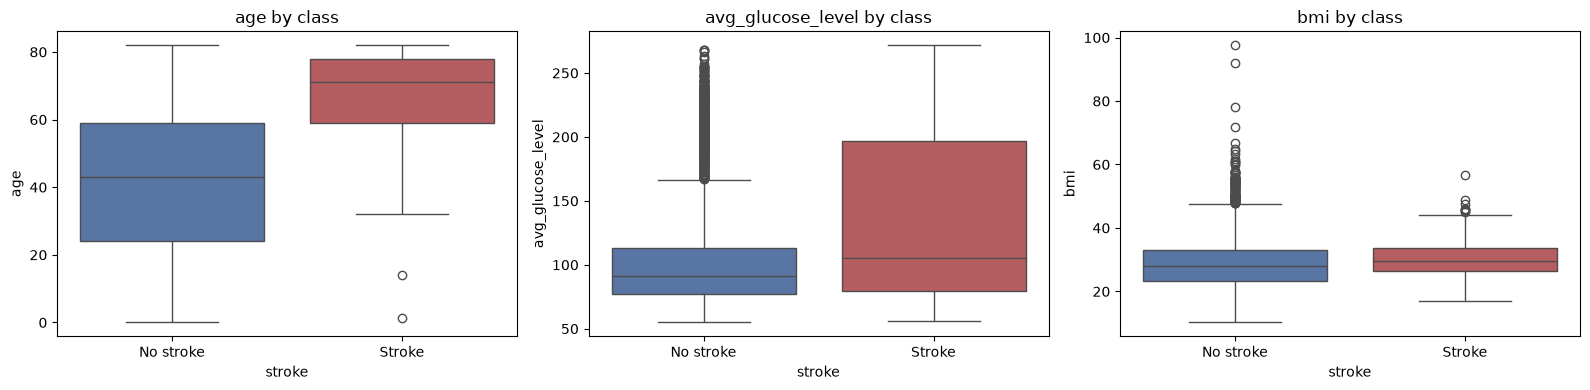

In [8]:
# The three continuous predictors by class
print(stroke.groupby('stroke')[['age', 'avg_glucose_level', 'bmi']].agg(['mean', 'median']).round(1))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, column in zip(axes, ['age', 'avg_glucose_level', 'bmi']):
    sns.boxplot(data=stroke, x='stroke', y=column, ax=ax, hue='stroke', palette=['#4c72b0', '#c44e52'], legend=False)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['No stroke', 'Stroke'])
    ax.set_title(column + ' by class')
plt.tight_layout()
plt.show()

Each panel is a pair of box plots, one per class. The box holds the middle half of the people, the line inside is the median, the whiskers reach the values still close to the box and the dots beyond are the extremes.

Age is the predictor that separates the classes. The median age of the people who had a stroke is 71, against 43 for the others, and the stroke box sits entirely above the middle of the no-stroke box. Glucose separates less: the medians are 105 against 92, but the stroke box is wider and its upper whisker reaches the diabetic range, so high glucose is a risk factor for a part of the stroke group only. The body mass index barely moves, 29.7 against 28.0, so on its own it will contribute little.

In [9]:
# Stroke rate by age band
AGE_BANDS = [0, 40, 50, 60, 70, 80, 90]
by_age = stroke.groupby(pd.cut(stroke['age'], AGE_BANDS), observed=True)['stroke'].agg(['mean', 'count'])
by_age['mean'] = (by_age['mean'] * 100).round(1)
by_age.columns = ['Stroke rate %', 'People']
print(by_age)

          Stroke rate %  People
age                            
(0, 40]             0.4    2244
(40, 50]            2.0     739
(50, 60]            6.0     823
(60, 70]            8.2     594
(70, 80]           17.7     594
(80, 90]           19.8     116


The rate climbs with every band: 0.4 percent under 40, 2.0 in the forties, 6.0 in the fifties, 8.2 in the sixties, 17.7 in the seventies and 19.8 above 80. A person over 70 is about fifty times more likely to have had a stroke than a person under 40. This is the relationship the sigmoid will fit, a probability that stays near zero for decades and then rises steeply.

In [10]:
# Is the missing body mass index informative on its own
missing_rate = stroke.groupby(stroke['bmi'].isna())['stroke'].agg(['mean', 'count'])
missing_rate['mean'] = (missing_rate['mean'] * 100).round(1)
missing_rate.index = ['bmi present', 'bmi missing']
missing_rate.columns = ['Stroke rate %', 'People']
print(missing_rate)

             Stroke rate %  People
bmi present            4.3    4909
bmi missing           19.9     201


This is the reason the missing values were not simply filled at the start. Among the 201 people without a body mass index, 19.9 percent had a stroke, against 4.3 percent of the rest, more than four times the rate. A missing measurement is not random here: it is likely that the index was not taken because the person was admitted in an emergency, that is, with the stroke. So the fact that `bmi` is missing carries information the model must keep. The preparation fills the gap with the median so the column stays numeric, and adds a 0 or 1 column that records that it was missing.

In [11]:
# Preparation. The Other gender row is removed, the missing bmi is recorded in
# its own column and filled with the median, and the text columns are encoded
stroke = stroke[stroke['gender'] != 'Other'].copy()

stroke['bmi_missing'] = stroke['bmi'].isna().astype(int)
BMI_FILL = stroke['bmi'].median()
stroke['bmi'] = stroke['bmi'].fillna(BMI_FILL)

# Two-value columns become a single 0 or 1 column
stroke['gender'] = (stroke['gender'] == 'Male').astype(int)
stroke['ever_married'] = (stroke['ever_married'] == 'Yes').astype(int)
stroke['Residence_type'] = (stroke['Residence_type'] == 'Urban').astype(int)

# Columns with more than two values become one 0 or 1 column per value, dropping
# the first value of each as the reference the others are compared against
MULTI_VALUE = ['work_type', 'smoking_status']
encoded = pd.get_dummies(stroke.drop(columns=['id']), columns=MULTI_VALUE, drop_first=True, dtype=int)

TARGET = 'stroke'
FEATURES = [c for c in encoded.columns if c != TARGET]
print("Predictors:", FEATURES)
encoded.head()

Predictors: ['gender', 'age', 'hypertension', 'heart_disease', 'ever_married', 'Residence_type', 'avg_glucose_level', 'bmi', 'bmi_missing', 'work_type_Never_worked', 'work_type_Private', 'work_type_Self-employed', 'work_type_children', 'smoking_status_formerly smoked', 'smoking_status_never smoked', 'smoking_status_smokes']


,gender,age,hypertension,heart_disease,ever_married,Residence_type,avg_glucose_level,bmi,stroke,bmi_missing,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes
0,1,67.0,0,1,1,1,228.69,36.6,1,0,0,1,0,0,1,0,0
1,0,61.0,0,0,1,0,202.21,28.1,1,1,0,0,1,0,0,1,0
2,1,80.0,0,1,1,0,105.92,32.5,1,0,0,1,0,0,0,1,0
3,0,49.0,0,0,1,1,171.23,34.4,1,0,0,1,0,0,0,0,1
4,0,79.0,1,0,1,0,174.12,24.0,1,0,0,0,1,0,0,1,0


The table is now entirely numeric: 16 predictors and the target. `gender` reads 1 for male, `ever_married` 1 for yes, `Residence_type` 1 for urban, and `work_type` and `smoking_status` became three and four columns each, with government job and Unknown as the reference values.

age                               0.245
bmi_missing                       0.141
heart_disease                     0.135
avg_glucose_level                 0.132
hypertension                      0.128
ever_married                      0.108
smoking_status_formerly smoked    0.065
work_type_Self-employed           0.062
bmi                               0.036
Residence_type                    0.015
work_type_Private                 0.012
gender                            0.009
smoking_status_smokes             0.009
smoking_status_never smoked      -0.004
work_type_Never_worked           -0.015
work_type_children               -0.084
Name: stroke, dtype: float64


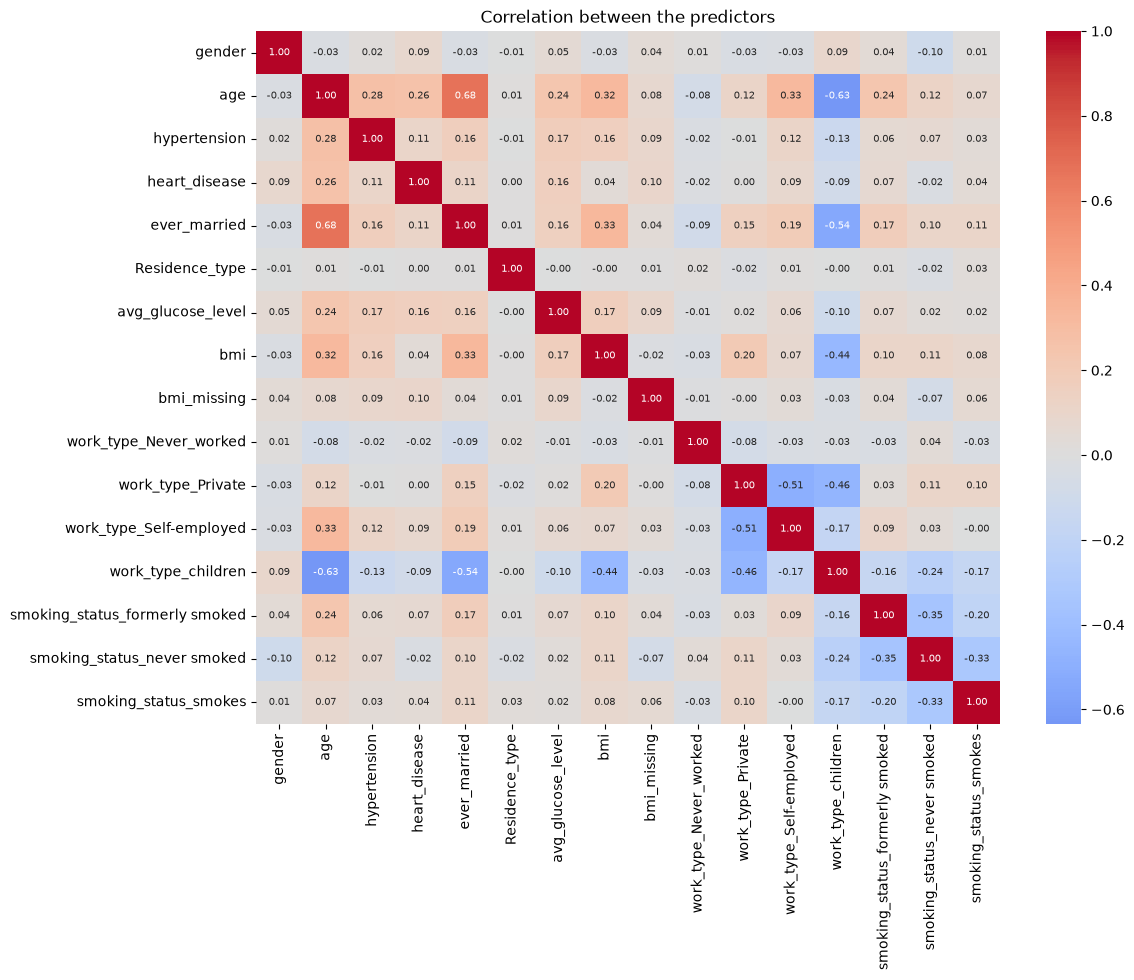

In [12]:
# Correlation of each predictor with the target
target_correlation = encoded.corr()[TARGET].drop(TARGET).sort_values(ascending=False)
print(target_correlation.round(3))

plt.figure(figsize=(12, 9))
sns.heatmap(encoded[FEATURES].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, annot_kws={'size': 7})
plt.title('Correlation between the predictors')
plt.show()

With a 0 or 1 target the correlation is a rough ranking rather than a precise number, and it ranks age first at 0.25, followed by the missing bmi flag at 0.14, heart disease, glucose and hypertension, all near 0.13. Residence type and gender are at zero. In the heatmap the only notable pairs are `age` with `ever_married` at 0.68 and `age` with `work_type_children` at -0.64, which are the age effects seen in the rates. None is above 0.75, so the slopes of the logistic regression will be readable, though the marriage and children slopes should be read as age in disguise.

In [13]:
# Stratified 75 / 25 split, so both sides keep the 4.9 percent of strokes
X = encoded[FEATURES]
y = encoded[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y)
print("Training people:", len(X_train), "with", int(y_train.sum()), "strokes")
print("Test people:", len(X_test), "with", int(y_test.sum()), "strokes")

Training people: 3831 with 187 strokes
Test people: 1278 with 62 strokes


The split is stratified, meaning both sides receive the same share of strokes, because a plain random split could leave the test set with a handful of cases and the recall would measure luck. Training keeps 3,831 people with 187 strokes and testing 1,278 people with 62.

## Machine Learning Model (CRISP-DM 4: Modeling)

A logistic regression is fitted inside a pipeline whose first step standardizes every predictor, subtracting the mean and dividing by the standard deviation, so that a slope on age and a slope on hypertension are on the same scale and can be compared. The model is trained by gradient descent on the binary cross entropy, the loss taught in the course, which scikit-learn does internally.

Two versions are fitted. Model A is the plain logistic regression, the literal reading of the technique. Model B tells the model that a stroke weighs as much as the 19 non strokes it is outnumbered by, through `class_weight='balanced'`, which is the standard answer to the imbalance found in the exploration. Both are evaluated on the same test people.

### Model A: plain logistic regression

In [14]:
model_plain = Pipeline([
    ('scale', StandardScaler()),
    ('logistic', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
]).fit(X_train, y_train)

# The slope of each predictor on the standardized scale: positive raises the
# probability of a stroke, negative lowers it
slopes_plain = pd.Series(model_plain.named_steps['logistic'].coef_[0], index=FEATURES).sort_values()
print(slopes_plain.round(3))

work_type_Self-employed          -0.096
ever_married                     -0.065
work_type_Never_worked           -0.039
gender                           -0.019
Residence_type                   -0.002
work_type_Private                 0.002
smoking_status_never smoked       0.007
bmi                               0.016
heart_disease                     0.030
smoking_status_formerly smoked    0.070
work_type_children                0.092
hypertension                      0.108
smoking_status_smokes             0.109
avg_glucose_level                 0.181
bmi_missing                       0.288
age                               1.597
dtype: float64


The slopes are in log-odds per standard deviation of the predictor, and what matters is their sign and their relative size. Age dominates with 1.60, and the next largest, the missing bmi flag at 0.29 and glucose at 0.18, are more than five times smaller. That matches the exploration, where age separated the classes and everything else moved the rate by a few points. The body mass index itself has a slope near zero and the marriage slope is slightly negative once age is in the model, which confirms that the 6.6 percent rate of married people was age.

Threshold                0.500
Accuracy                 0.952
Sensitivity (recall)     0.032
Specificity              0.999
Precision                0.667
F1                       0.062
AUC                      0.845
Strokes found            2.000
Strokes missed          60.000
False alarms             1.000
Name: Model A, dtype: float64


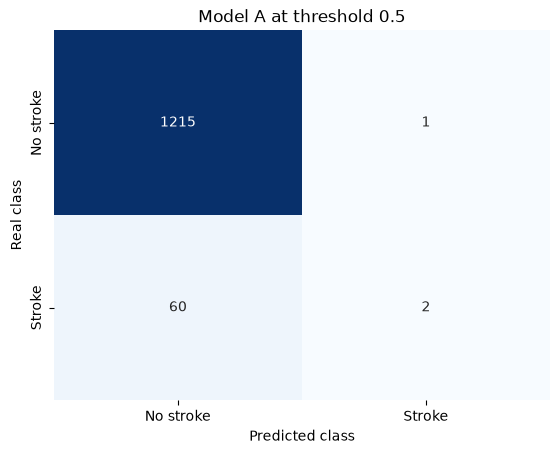

In [15]:
# Evaluation helper: confusion matrix, the four rates and the AUC, at a chosen threshold
def evaluate(model, threshold, name):
    probability = model.predict_proba(X_test)[:, 1]
    predicted = (probability >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, predicted).ravel()
    return pd.Series({
        'Threshold': threshold,
        'Accuracy': accuracy_score(y_test, predicted),
        'Sensitivity (recall)': recall_score(y_test, predicted),
        'Specificity': tn / (tn + fp),
        'Precision': precision_score(y_test, predicted, zero_division=0),
        'F1': f1_score(y_test, predicted),
        'AUC': roc_auc_score(y_test, probability),
        'Strokes found': tp, 'Strokes missed': fn, 'False alarms': fp,
    }, name=name)

def show_confusion(model, threshold, title):
    predicted = (model.predict_proba(X_test)[:, 1] >= threshold).astype(int)
    matrix = confusion_matrix(y_test, predicted)
    sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['No stroke', 'Stroke'], yticklabels=['No stroke', 'Stroke'])
    plt.xlabel('Predicted class')
    plt.ylabel('Real class')
    plt.title(title)
    plt.show()

DEFAULT_THRESHOLD = 0.5
print(evaluate(model_plain, DEFAULT_THRESHOLD, 'Model A').round(3))
show_confusion(model_plain, DEFAULT_THRESHOLD, 'Model A at threshold 0.5')

The confusion matrix has the real class in rows and the predicted class in columns, so the top left cell is people correctly called healthy, the bottom right is strokes correctly found, the top right is false alarms and the bottom left is strokes missed. Sensitivity, which the course also calls recall, is the share of real strokes found. Specificity is the share of healthy people correctly left alone. Precision is the share of the people flagged who really had a stroke. The AUC is the area under the ROC curve drawn later, from 0.5 for a coin toss to 1 for a perfect ranking.

The plain model has an accuracy of 0.952, and it is worthless: it found 2 of the 62 strokes in the test set and missed 60, a sensitivity of 0.032. The accuracy is exactly the 95 percent that answering "no" to everyone would give. What happened is that the model was trained on 3,831 people of whom 187 had a stroke, so the cheapest way to lower its loss was to predict a low probability for nearly everyone, and with the default threshold of 0.5 nearly no one crosses it. The AUC of 0.845, however, says the ranking behind those probabilities is good: the people who had a stroke do receive higher probabilities than the others, they just do not reach 0.5. The problem is the threshold and the weight of the classes, not the information.

### Model B: logistic regression with balanced class weights

work_type_Never_worked           -0.169
work_type_Self-employed          -0.130
gender                           -0.123
work_type_Private                -0.014
ever_married                      0.023
smoking_status_never smoked       0.027
Residence_type                    0.029
heart_disease                     0.053
bmi                               0.063
smoking_status_formerly smoked    0.099
hypertension                      0.196
avg_glucose_level                 0.212
smoking_status_smokes             0.213
bmi_missing                       0.347
work_type_children                0.407
age                               1.822
dtype: float64

Threshold                 0.500
Accuracy                  0.751
Sensitivity (recall)      0.806
Specificity               0.748
Precision                 0.140
F1                        0.239
AUC                       0.843
Strokes found            50.000
Strokes missed           12.000
False alarms            306.000
Name: Model B, dtype: fl

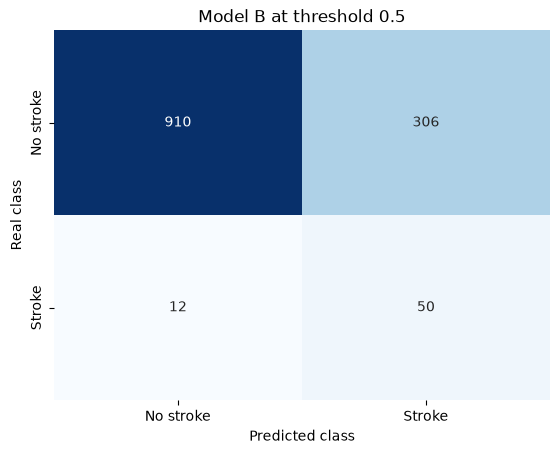

In [16]:
model_balanced = Pipeline([
    ('scale', StandardScaler()),
    ('logistic', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE)),
]).fit(X_train, y_train)

slopes_balanced = pd.Series(model_balanced.named_steps['logistic'].coef_[0], index=FEATURES).sort_values()
print(slopes_balanced.round(3))
print()
print(evaluate(model_balanced, DEFAULT_THRESHOLD, 'Model B').round(3))
show_confusion(model_balanced, DEFAULT_THRESHOLD, 'Model B at threshold 0.5')

With balanced weights every stroke in training counts as much as about twenty healthy people, so the loss can no longer be lowered by ignoring them. The slopes keep the same leader, age at 1.82 far ahead of the missing bmi flag at 0.35, smoking at 0.21, glucose at 0.21 and hypertension at 0.20, so the model learned the same facts, and the AUC is 0.843 against 0.845, practically the same, since weighting barely changes which people rank above which.

What changes is the matrix. At the same threshold of 0.5 the model now finds 50 of the 62 strokes, a sensitivity of 0.81, at the cost of 306 false alarms among the 1,216 healthy people, a specificity of 0.75. Accuracy drops to 0.751, and that drop is the price of a screening tool that actually screens. Precision is 0.14: of every hundred people flagged, fourteen had a stroke. For a check-up that is acceptable, for a treatment it would not be.

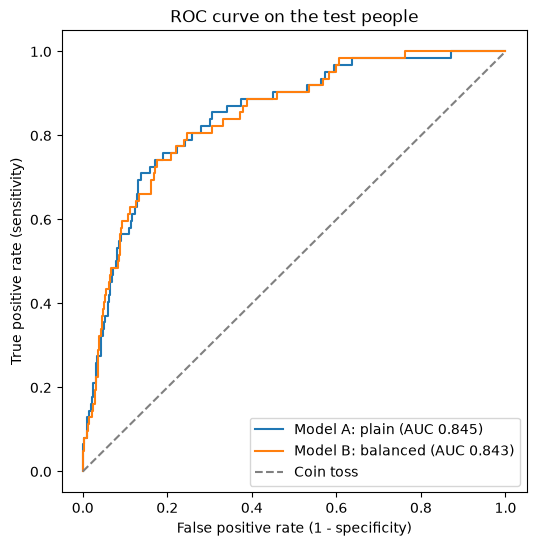

In [17]:
# The ROC curve of both models: sensitivity against 1 - specificity at every threshold
plt.figure(figsize=(6, 6))
for model, name in [(model_plain, 'Model A: plain'), (model_balanced, 'Model B: balanced')]:
    probability = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, probability)
    plt.plot(fpr, tpr, label='%s (AUC %.3f)' % (name, roc_auc_score(y_test, probability)))
plt.plot([0, 1], [0, 1], linestyle='--', color='grey', label='Coin toss')
plt.xlabel('False positive rate (1 - specificity)')
plt.ylabel('True positive rate (sensitivity)')
plt.title('ROC curve on the test people')
plt.legend()
plt.show()

The ROC curve traces every threshold at once: each point is the sensitivity the model reaches, vertically, at the cost of the false alarm rate it produces, horizontally. The dashed diagonal is a model with no information, and a curve that hugs the top left corner is a model that finds the strokes before it starts flagging the healthy. The two curves lie on top of each other, which is the visual version of the nearly equal AUC: Models A and B rank people identically, and the whole difference between them is where on this curve the threshold of 0.5 lands. This is why the next cell treats the threshold as the decision it is.

In [18]:
# How the balanced model behaves at several thresholds
THRESHOLDS = [0.3, 0.4, 0.5, 0.6, 0.7]
sweep = pd.concat([evaluate(model_balanced, t, 'threshold %.1f' % t) for t in THRESHOLDS], axis=1).T
print(sweep.round(3).to_string())

               Threshold  Accuracy  Sensitivity (recall)  Specificity  Precision     F1    AUC  Strokes found  Strokes missed  False alarms
threshold 0.3        0.3     0.624                 0.887        0.611      0.104  0.186  0.843           55.0             7.0         473.0
threshold 0.4        0.4     0.689                 0.823        0.682      0.116  0.204  0.843           51.0            11.0         387.0
threshold 0.5        0.5     0.751                 0.806        0.748      0.140  0.239  0.843           50.0            12.0         306.0
threshold 0.6        0.6     0.810                 0.742        0.813      0.168  0.275  0.843           46.0            16.0         227.0
threshold 0.7        0.7     0.854                 0.661        0.863      0.198  0.305  0.843           41.0            21.0         166.0


Each row is the same model with a different cut. Lowering the threshold to 0.3 finds 55 of the 62 strokes but flags 473 healthy people, four in ten. Raising it to 0.7 flags only 166 healthy people but misses 21 strokes. The threshold of 0.5 sits between them, with 50 found, 12 missed and 306 false alarms. There is no free choice here, every stroke recovered costs more healthy people called in, and the right cut depends on what the clinic can afford. For a tool that sends people to a check-up, the missed strokes are the expensive error, and a threshold of 0.5 with balanced weights, or 0.4 if the clinic can absorb more appointments, is the reasonable region. The default of 0.5 is kept and the probability itself is stored, so the API can apply whichever cut the clinic decides.

## Evaluation (CRISP-DM 5)

The kept model is Model B at a threshold of 0.5. Its full report on the test people follows, along with the plain model for the record.

In [19]:
comparison = pd.concat([evaluate(model_plain, DEFAULT_THRESHOLD, 'Model A: plain'),
                        evaluate(model_balanced, DEFAULT_THRESHOLD, 'Model B: balanced')], axis=1)
print(comparison.round(3))
print()
print(classification_report(y_test, model_balanced.predict(X_test), target_names=['No stroke', 'Stroke']))

                      Model A: plain  Model B: balanced
Threshold                      0.500              0.500
Accuracy                       0.952              0.751
Sensitivity (recall)           0.032              0.806
Specificity                    0.999              0.748
Precision                      0.667              0.140
F1                             0.062              0.239
AUC                            0.845              0.843
Strokes found                  2.000             50.000
Strokes missed                60.000             12.000
False alarms                   1.000            306.000

              precision    recall  f1-score   support

   No stroke       0.99      0.75      0.85      1216
      Stroke       0.14      0.81      0.24        62

    accuracy                           0.75      1278
   macro avg       0.56      0.78      0.55      1278
weighted avg       0.95      0.75      0.82      1278



The report lists, for each class, the precision, the recall and their combination F1, and the support, which is the number of test people in the class. For the stroke class the balanced model reaches a recall of 0.81 with a precision of 0.14, and for the healthy class a recall of 0.75 with a precision of 0.99, that is, when the model says a person is healthy it is almost always right. The macro average F1 of the balanced model is low because the stroke F1 is 0.24, and that number is honest: with 62 strokes among 1,278 people, any model that catches most of them will flag many healthy people too.

Model A wins on accuracy, 0.952 against 0.751, and that is stated plainly before the choice. It is a hollow win, since it comes from finding two strokes in 62. The evaluation that matters for a screening tool is the 50 strokes found by Model B against the 2 found by Model A, at practically the same AUC.

## Results (CRISP-DM 6: Deployment)

The model kept is a logistic regression with balanced class weights on 16 predictors, applied at a threshold of 0.5. On the 1,278 test people it reaches an AUC of 0.843, a sensitivity of 0.81, a specificity of 0.75, a precision of 0.14 and an accuracy of 0.751. The plain logistic regression, built first, reaches an accuracy of 0.952 with a sensitivity of 0.032, and it was rejected because a screening tool that misses 60 of 62 strokes is not a screening tool. The trade is stated in the units of the problem: 48 more strokes found out of 62, in exchange for 305 more healthy people out of 1,216 sent to a check-up they did not need.

Age is the predictor, with a slope five times larger than any other. Glucose, hypertension, heart disease and smoking add a little each, the missing body mass flag carries the emergency admission signal found in the exploration, and gender, residence and the body mass index itself add nothing. The model is recommended for the assistant as a risk indicator, with two limitations. Its precision of 0.13 means that a positive answer is a reason for a check-up, never a diagnosis, and it was trained on a file where the true cause of the stroke and the moment of the measurements are unknown, so a high glucose in a person who has just had a stroke may be an effect rather than a cause. The pipeline, which includes the scaler, is saved below with its predictor list and the fill value of `bmi`, so the REST API can build the same 16 columns and predict.

In [20]:
bundle = {
    'model': model_balanced,
    'features': FEATURES,
    'target': TARGET,
    'threshold': DEFAULT_THRESHOLD,
    'bmi_fill': float(BMI_FILL),
    'reference_categories': {'work_type': 'Govt_job', 'smoking_status': 'Unknown'},
}
MODEL_PATH = os.path.join(MODELS_DIR, 'stroke_classification.joblib')
joblib.dump(bundle, MODEL_PATH)
print("Saved to", MODEL_PATH)

Saved to ../models/stroke_classification.joblib


In [21]:
# Reload and score one person by hand: a 68 year old married man with
# hypertension, glucose 140, bmi 31, private job, former smoker, urban
loaded = joblib.load(MODEL_PATH)
person = pd.DataFrame([dict.fromkeys(loaded['features'], 0)])
person.loc[0, ['gender', 'age', 'hypertension', 'heart_disease', 'ever_married', 'Residence_type',
               'avg_glucose_level', 'bmi', 'bmi_missing']] = [1, 68, 1, 0, 1, 1, 140.0, 31.0, 0]
person.loc[0, ['work_type_Private', 'smoking_status_formerly smoked']] = [1, 1]
probability = loaded['model'].predict_proba(person)[0, 1]
print("Probability of stroke: %.3f" % probability)
print("Flagged for a check-up:", bool(probability >= loaded['threshold']))

Probability of stroke: 0.792
Flagged for a check-up: True


The reloaded pipeline gives this 68 year old hypertensive former smoker a probability of 0.79, well above the threshold, so he would be flagged, which is what the exploration's 8.2 percent rate for his age band, tripled by hypertension, implies. The API repeats this call: build the 16 columns, predict the probability and compare it with the stored threshold.